In [1]:
# 1. Imports and configuration

from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

DATA_DIR = Path(r"C:\Users\bimal\OneDrive\Desktop\EVIDENT\data\raw\phishing\model 1")
DATA_PATH = DATA_DIR / "PhiUSIIL_Phishing_URL_Dataset.csv"

MODEL_DIR = Path(r"C:\Users\bimal\OneDrive\Desktop\EVIDENT\models\phishing")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset:", DATA_PATH)
print("Exists:", DATA_PATH.exists())
print("Model directory:", MODEL_DIR)

Dataset: C:\Users\bimal\OneDrive\Desktop\EVIDENT\data\raw\phishing\model 1\PhiUSIIL_Phishing_URL_Dataset.csv
Exists: True
Model directory: C:\Users\bimal\OneDrive\Desktop\EVIDENT\models\phishing


In [2]:
# 2. Load data

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}\n"
        "Check the Windows path and filename."
    )

df = pd.read_csv(DATA_PATH, low_memory=False)

print(f"Shape: {df.shape}")
display(df.head())

Shape: (235795, 56)


,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1


In [3]:
# 3. Schema inspection

print("Columns:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i:02d}. {col}")

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nTarget candidates:")
target_candidates = [
    c for c in df.columns
    if str(c).strip().lower() in {"label", "target", "class", "status", "result"}
]
print(target_candidates)


Columns:
01. FILENAME
02. URL
03. URLLength
04. Domain
05. DomainLength
06. IsDomainIP
07. TLD
08. URLSimilarityIndex
09. CharContinuationRate
10. TLDLegitimateProb
11. URLCharProb
12. TLDLength
13. NoOfSubDomain
14. HasObfuscation
15. NoOfObfuscatedChar
16. ObfuscationRatio
17. NoOfLettersInURL
18. LetterRatioInURL
19. NoOfDegitsInURL
20. DegitRatioInURL
21. NoOfEqualsInURL
22. NoOfQMarkInURL
23. NoOfAmpersandInURL
24. NoOfOtherSpecialCharsInURL
25. SpacialCharRatioInURL
26. IsHTTPS
27. LineOfCode
28. LargestLineLength
29. HasTitle
30. Title
31. DomainTitleMatchScore
32. URLTitleMatchScore
33. HasFavicon
34. Robots
35. IsResponsive
36. NoOfURLRedirect
37. NoOfSelfRedirect
38. HasDescription
39. NoOfPopup
40. NoOfiFrame
41. HasExternalFormSubmit
42. HasSocialNet
43. HasSubmitButton
44. HasHiddenFields
45. HasPasswordField
46. Bank
47. Pay
48. Crypto
49. HasCopyrightInfo
50. NoOfImage
51. NoOfCSS
52. NoOfJS
53. NoOfSelfRef
54. NoOfEmptyRef
55. NoOfExternalRef
56. label

Data types:


,dtype
FILENAME,str
URL,str
URLLength,int64
Domain,str
DomainLength,int64
IsDomainIP,int64
TLD,str
URLSimilarityIndex,float64
CharContinuationRate,float64
TLDLegitimateProb,float64



Target candidates:
['label']


In [4]:
# 4. Identify target column

TARGET_COLUMN = None

preferred_targets = ["label", "target", "class", "status", "result"]

for candidate in preferred_targets:
    matches = [c for c in df.columns if str(c).strip().lower() == candidate]
    if matches:
        TARGET_COLUMN = matches[0]
        break

if TARGET_COLUMN is None:
    raise ValueError(
        "Could not automatically identify the target column. "
        "Inspect df.columns and set TARGET_COLUMN manually."
    )

print("Target column:", TARGET_COLUMN)
print("\nTarget distribution:")
display(df[TARGET_COLUMN].value_counts(dropna=False))

Target column: label

Target distribution:


label
1    134850
0    100945
Name: count, dtype: int64

In [5]:
# 5. Basic data quality checks

print("Missing values:")
missing = df.isna().sum().sort_values(ascending=False)
display(missing[missing > 0].to_frame("missing_count").head(30))

print("Duplicate rows:", df.duplicated().sum())

if "URL" in df.columns:
    print("Duplicate URLs:", df["URL"].duplicated().sum())

Missing values:


,missing_count


Duplicate rows: 0
Duplicate URLs: 425


In [6]:
# 6. Build the initial feature matrix

# Obvious non-model fields / raw text / identifiers.
EXCLUDE_COLUMNS = {
    TARGET_COLUMN,
    "FILENAME",
    "filename",
    "URL",
    "url",
    "Domain",
    "domain",
    "TLD",
    "tld",
    "Title",
    "title",
}

feature_candidates = [c for c in df.columns if c not in EXCLUDE_COLUMNS]

# Keep numeric/bool features for the first model.
numeric_features = df[feature_candidates].select_dtypes(
    include=["number", "bool"]
).columns.tolist()

if not numeric_features:
    raise ValueError("No numeric/binary features were found.")

X = df[numeric_features].copy()
y_raw = df[TARGET_COLUMN].copy()

print(f"Numeric/binary features: {len(numeric_features)}")
print(numeric_features)
print("\nFeature matrix:", X.shape)

Numeric/binary features: 50
['URLLength', 'DomainLength', 'IsDomainIP', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef']

Feature matrix: (235795, 50)


In [7]:
# 7. Normalize binary target

print("Original target values:")
print(y_raw.value_counts(dropna=False))

unique_values = list(pd.Series(y_raw.dropna().unique()))

if len(unique_values) != 2:
    raise ValueError(
        f"Expected a binary target, but found {len(unique_values)} unique values: "
        f"{unique_values}"
    )

# Handle common numeric binary labels directly.
if set(pd.Series(unique_values).astype(str)) <= {"0", "1"}:
    y = pd.to_numeric(y_raw, errors="coerce")
else:
    # Common text labels.
    normalized = y_raw.astype(str).str.strip().str.lower()

    positive_terms = {
        "1", "phishing", "phish", "malicious", "malware",
        "bad", "fraud", "fake"
    }
    negative_terms = {
        "0", "legitimate", "benign", "safe", "good",
        "normal", "clean"
    }

    mapped = normalized.map(
        lambda v: 1 if v in positive_terms
        else (0 if v in negative_terms else np.nan)
    )

    if mapped.isna().any():
        raise ValueError(
            "Target contains labels that could not be safely mapped to 0/1. "
            f"Values: {sorted(normalized.unique())}"
        )

    y = mapped.astype(int)

if y.isna().any():
    raise ValueError("Target contains missing/unusable values.")

y = y.astype(int)

print("\nNormalized target:")
print(y.value_counts())

Original target values:
label
1    134850
0    100945
Name: count, dtype: int64

Normalized target:
label
1    134850
0    100945
Name: count, dtype: int64


In [8]:
# 8. Deduplicate feature/label records

model_df = X.copy()
model_df["__target__"] = y.values

before = len(model_df)
model_df = model_df.drop_duplicates()

conflicts = (
    model_df.groupby(numeric_features)["__target__"]
    .nunique()
)
conflicting_rows = int((conflicts > 1).sum())

print("Rows before:", before)
print("Rows after exact deduplication:", len(model_df))
print("Potential conflicting feature groups:", conflicting_rows)

X = model_df[numeric_features]
y = model_df["__target__"].astype(int)

print("Final modeling shape:", X.shape)


Rows before: 235795
Rows after exact deduplication: 234987
Potential conflicting feature groups: 0
Final modeling shape: (234987, 50)


In [9]:
# 9. Stratified train/validation/test split

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=RANDOM_STATE,
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=RANDOM_STATE,
)

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

print("\nTrain distribution:")
print(y_train.value_counts(normalize=True))

print("\nValidation distribution:")
print(y_val.value_counts(normalize=True))

print("\nTest distribution:")
print(y_test.value_counts(normalize=True))

Train: (164490, 50) (164490,)
Validation: (35248, 50) (35248,)
Test: (35249, 50) (35249,)

Train distribution:
__target__
1    0.573859
0    0.426141
Name: proportion, dtype: float64

Validation distribution:
__target__
1    0.573877
0    0.426123
Name: proportion, dtype: float64

Test distribution:
__target__
1    0.57386
0    0.42614
Name: proportion, dtype: float64


In [10]:
# 10. Baseline model evaluation helper

def evaluate_model(name, model, X_fit, y_fit, X_eval, y_eval):
    model.fit(X_fit, y_fit)

    pred = model.predict(X_eval)
    prob = model.predict_proba(X_eval)[:, 1]

    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_eval, pred),
        "Precision": precision_score(y_eval, pred, zero_division=0),
        "Recall": recall_score(y_eval, pred, zero_division=0),
        "F1": f1_score(y_eval, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_eval, prob),
    }

    print(f"\n{name}")
    print(classification_report(
        y_eval,
        pred,
        target_names=["Legitimate", "Phishing"],
        zero_division=0
    ))

    return model, metrics


baseline_models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=None,
        )),
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced_subsample",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )),
    ]),
}

baseline_results = []
fitted_baselines = {}

for name, model in baseline_models.items():
    fitted, metrics = evaluate_model(
        name, model,
        X_train, y_train,
        X_val, y_val
    )
    fitted_baselines[name] = fitted
    baseline_results.append(metrics)

baseline_results_df = pd.DataFrame(baseline_results).sort_values(
    by=["F1", "ROC_AUC"],
    ascending=False
)

display(baseline_results_df)


Logistic Regression
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     15020
    Phishing       1.00      1.00      1.00     20228

    accuracy                           1.00     35248
   macro avg       1.00      1.00      1.00     35248
weighted avg       1.00      1.00      1.00     35248


Random Forest
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     15020
    Phishing       1.00      1.00      1.00     20228

    accuracy                           1.00     35248
   macro avg       1.00      1.00      1.00     35248
weighted avg       1.00      1.00      1.00     35248



,Model,Accuracy,Precision,Recall,F1,ROC_AUC
1,Random Forest,1.000000,1.000000,1.000000,1.000000,1.000000
0,Logistic Regression,0.999376,0.999456,0.999456,0.999456,0.999998


In [11]:
# 11. XGBoost training

try:
    from xgboost import XGBClassifier
except ImportError as exc:
    raise ImportError(
        "XGBoost is not installed in this Python environment. "
        "Install it with: pip install xgboost"
    ) from exc

xgb_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", XGBClassifier(
        n_estimators=500,
        max_depth=8,
        learning_rate=0.08,
        subsample=0.85,
        colsample_bytree=0.85,
        min_child_weight=2,
        reg_lambda=1.0,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )),
])

xgb_fitted, xgb_metrics = evaluate_model(
    "XGBoost",
    xgb_model,
    X_train,
    y_train,
    X_val,
    y_val
)

print("XGBoost validation metrics:")
display(pd.DataFrame([xgb_metrics]))


XGBoost
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     15020
    Phishing       1.00      1.00      1.00     20228

    accuracy                           1.00     35248
   macro avg       1.00      1.00      1.00     35248
weighted avg       1.00      1.00      1.00     35248

XGBoost validation metrics:


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,XGBoost,1.0,1.0,1.0,1.0,1.0


In [12]:
# 12. Model comparison

all_results = baseline_results + [xgb_metrics]

results_df = pd.DataFrame(all_results).sort_values(
    by=["F1", "ROC_AUC"],
    ascending=False
).reset_index(drop=True)

display(results_df)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Random Forest,1.000000,1.000000,1.000000,1.000000,1.000000
1,XGBoost,1.000000,1.000000,1.000000,1.000000,1.000000
2,Logistic Regression,0.999376,0.999456,0.999456,0.999456,0.999998


In [13]:
# 13. Select best model and evaluate on the final test set

candidate_models = {
    **fitted_baselines,
    "XGBoost": xgb_fitted,
}

best_name = results_df.iloc[0]["Model"]
best_model = candidate_models[best_name]

print("Selected model:", best_name)

test_pred = best_model.predict(X_test)
test_prob = best_model.predict_proba(X_test)[:, 1]

test_metrics = {
    "Model": best_name,
    "Accuracy": accuracy_score(y_test, test_pred),
    "Precision": precision_score(y_test, test_pred, zero_division=0),
    "Recall": recall_score(y_test, test_pred, zero_division=0),
    "F1": f1_score(y_test, test_pred, zero_division=0),
    "ROC_AUC": roc_auc_score(y_test, test_prob),
}

print("\nFinal test metrics:")
display(pd.DataFrame([test_metrics]))

print("\nClassification report:")
print(classification_report(
    y_test,
    test_pred,
    target_names=["Legitimate", "Phishing"],
    zero_division=0
))

Selected model: Random Forest

Final test metrics:


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Random Forest,1.0,1.0,1.0,1.0,1.0



Classification report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     15021
    Phishing       1.00      1.00      1.00     20228

    accuracy                           1.00     35249
   macro avg       1.00      1.00      1.00     35249
weighted avg       1.00      1.00      1.00     35249



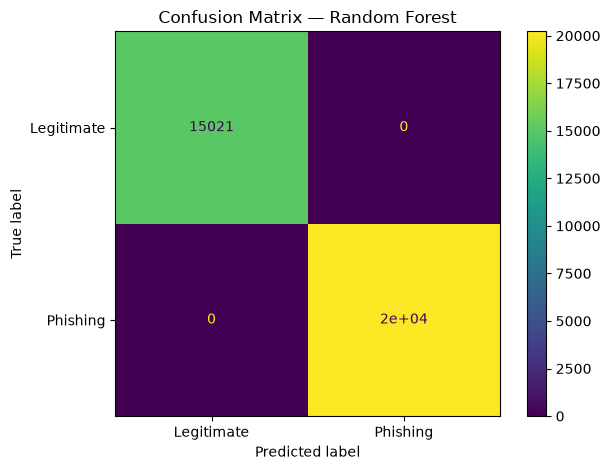

In [14]:
# 14. Confusion matrix

cm = confusion_matrix(y_test, test_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate", "Phishing"]
)

disp.plot()
plt.title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.show()

In [15]:
# 15. Feature importance for XGBoost

if best_name == "XGBoost":
    xgb_estimator = best_model.named_steps["model"]

    importance_df = (
        pd.DataFrame({
            "feature": numeric_features,
            "importance": xgb_estimator.feature_importances_,
        })
        .sort_values("importance", ascending=False)
        .head(20)
    )

    display(importance_df)

    plt.figure(figsize=(10, 7))
    plt.barh(
        importance_df["feature"][::-1],
        importance_df["importance"][::-1]
    )
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.title("Top 20 XGBoost Features")
    plt.tight_layout()
    plt.show()
else:
    print("Feature importance visualization is currently configured for XGBoost.")

Feature importance visualization is currently configured for XGBoost.


In [16]:
# 16. Save model and metadata

import joblib
from datetime import datetime

MODEL_PATH = MODEL_DIR / "phishing_model.pkl"
METADATA_PATH = MODEL_DIR / "model_metadata.json"

joblib.dump(best_model, MODEL_PATH)

metadata = {
    "model_name": best_name,
    "task": "binary phishing URL classification",
    "positive_class": "phishing",
    "negative_class": "legitimate",
    "feature_count": len(numeric_features),
    "features": numeric_features,
    "random_state": RANDOM_STATE,
    "dataset": "PhiUSIIL_Phishing_URL_Dataset.csv",
    "test_metrics": test_metrics,
    "created_at": datetime.now().isoformat(),
}

with open(METADATA_PATH, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print("Saved model:", MODEL_PATH)
print("Saved metadata:", METADATA_PATH)

Saved model: C:\Users\bimal\OneDrive\Desktop\EVIDENT\models\phishing\phishing_model.pkl
Saved metadata: C:\Users\bimal\OneDrive\Desktop\EVIDENT\models\phishing\model_metadata.json


In [17]:
# 17. Reload and test the saved model

loaded_model = joblib.load(MODEL_PATH)

sample = X_test.iloc[[0]]

prediction = int(loaded_model.predict(sample)[0])
probability = float(loaded_model.predict_proba(sample)[0, 1])

print("Prediction:", "PHISHING" if prediction == 1 else "LEGITIMATE")
print(f"Phishing probability: {probability:.4f}")

Prediction: PHISHING
Phishing probability: 1.0000


In [18]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path(r"C:\Users\bimal\OneDrive\Desktop\EVIDENT")

DATA_DIR = PROJECT_ROOT / "data" / "raw" / "phishing" / "model 1"

DATASET_PATH = DATA_DIR / "PhiUSIIL_Phishing_URL_Dataset.csv"

df = pd.read_csv(DATASET_PATH)

print("Dataset loaded successfully")
print("Shape:", df.shape)

Dataset loaded successfully
Shape: (235795, 56)
